# Employee Attrition Prediction System
### End-to-End Machine Learning Workflow: EDA, Modeling & Inference

**Author:** Infobharat Intern  
**Objective:** Build a machine learning decision-support system to analyze organizational factors and predict employee flight risk.

## 1. Importing Libraries and Project Modules
We import core data science libraries and modular project components.

In [1]:
import sys
from pathlib import Path

# Ensure project root is in sys.path
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.utils import DATA_FILE, FEATURE_COLUMNS, VALID_DEPARTMENTS
from src.generate_data import generate_synthetic_data, save_dataset
from src.preprocessing import load_dataset, clean_and_validate_data, prepare_train_test_data
from src.train_model import train_and_evaluate_models
from src.predict import AttritionPredictor

# Set plotting style
sns.set_theme(style="whitegrid")
%matplotlib inline

## 2. Loading the Dataset
We load the employee dataset from `data/employee_data.csv`. If it does not exist, we generate it automatically.

In [2]:
if not DATA_FILE.exists():
    print("Dataset not found. Generating reproducible synthetic dataset...")
    df_raw = generate_synthetic_data(n_samples=1000, random_seed=42)
    save_dataset(df_raw, DATA_FILE)
else:
    df_raw = load_dataset(DATA_FILE)

print(f"Loaded dataset shape: {df_raw.shape}")
df_raw.head()

Loaded dataset shape: (1000, 11)


,EmployeeID,Age,Department,MonthlyIncome,YearsAtCompany,JobSatisfaction,WorkLifeBalance,PerformanceRating,OverTime,DistanceFromHome,Attrition
0,EMP0001,24,Sales,74600.0,6,3,3,5,No,38,No
1,EMP0002,51,Marketing,76200.0,1,3,3,2,No,8,No
2,EMP0003,47,Engineering,116500.0,6,4,3,3,No,32,No
3,EMP0004,38,Sales,66200.0,2,3,4,2,No,17,No
4,EMP0005,38,Sales,86600.0,4,3,5,4,No,20,No


## 3. Data Integrity & Missing Values Inspection

In [3]:
df_clean, missing_stats = clean_and_validate_data(df_raw, drop_duplicates=True)
print("Missing Value Counts per Column:")
for col, count in missing_stats.items():
    print(f" - {col:20s}: {count}")

print("\nData Types:")
print(df_clean.dtypes)

Missing Value Counts per Column:
 - EmployeeID          : 0
 - Age                 : 0
 - Department          : 0
 - MonthlyIncome       : 0
 - YearsAtCompany      : 0
 - JobSatisfaction     : 0
 - WorkLifeBalance     : 0
 - PerformanceRating   : 0
 - OverTime            : 0
 - DistanceFromHome    : 0
 - Attrition           : 0

Data Types:
EmployeeID            object
Age                    int64
Department            object
MonthlyIncome        float64
YearsAtCompany         int64
JobSatisfaction        int64
WorkLifeBalance        int64
PerformanceRating      int64
OverTime              object
DistanceFromHome       int64
Attrition             object
dtype: object


## 4. Summary Statistics

In [4]:
df_clean.describe().round(2)

,Age,MonthlyIncome,YearsAtCompany,JobSatisfaction,WorkLifeBalance,PerformanceRating,DistanceFromHome
count,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00
mean,40.61,90921.30,5.26,3.21,3.21,3.24,22.92
std,11.55,24124.88,5.47,1.12,1.08,0.82,12.53
min,21.00,34000.00,0.00,1.00,1.00,1.00,1.00
25%,30.00,74475.00,1.00,2.00,3.00,3.00,12.00
50%,41.00,88050.00,4.00,3.00,3.00,3.00,22.00
75%,51.00,104825.00,7.25,4.00,4.00,4.00,33.00
max,60.00,197300.00,35.00,5.00,5.00,5.00,45.00


## 5. Target Attrition Distribution

           Count  Percentage (%)
Attrition                       
No           798            79.8
Yes          202            20.2


C:\Users\GAYATHRI\AppData\Local\Temp\ipykernel_13784\55228289.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, x='Attrition', palette=['#2ca02c', '#d62728'])


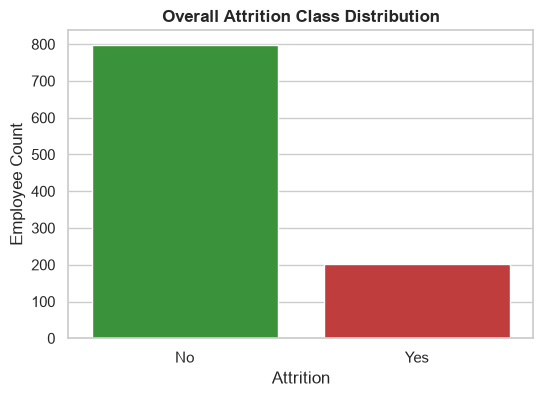

In [5]:
attrition_counts = df_clean['Attrition'].value_counts()
attrition_pcts = df_clean['Attrition'].value_counts(normalize=True) * 100

summary_df = pd.DataFrame({'Count': attrition_counts, 'Percentage (%)': attrition_pcts.round(2)})
print(summary_df)

plt.figure(figsize=(6, 4))
sns.countplot(data=df_clean, x='Attrition', palette=['#2ca02c', '#d62728'])
plt.title('Overall Attrition Class Distribution', fontsize=12, fontweight='bold')
plt.ylabel('Employee Count')
plt.show()

## 6. Exploratory Data Analysis & Visualizations
We investigate key organizational questions: departmental attrition rates, salary box plots, overtime impact, satisfaction ratings, and numerical correlations.

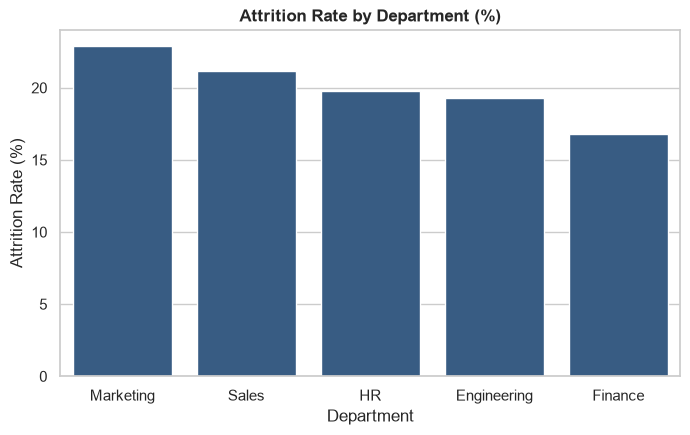

In [6]:
# Attrition by Department
dept_rates = df_clean.groupby('Department')['Attrition'].apply(lambda s: (s == 'Yes').mean() * 100).reset_index(name='Rate')

plt.figure(figsize=(8, 4.5))
sns.barplot(data=dept_rates.sort_values(by='Rate', ascending=False), x='Department', y='Rate', color='#2b5c8f')
plt.title('Attrition Rate by Department (%)', fontweight='bold')
plt.ylabel('Attrition Rate (%)')
plt.show()

C:\Users\GAYATHRI\AppData\Local\Temp\ipykernel_13784\1212536545.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='Attrition', y='MonthlyIncome', palette={'No': '#2ca02c', 'Yes': '#d62728'})


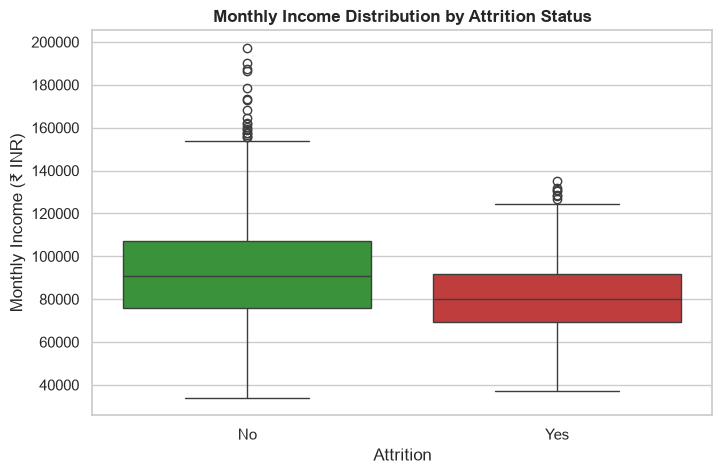

In [7]:
# Monthly Income Distribution vs Attrition
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_clean, x='Attrition', y='MonthlyIncome', palette={'No': '#2ca02c', 'Yes': '#d62728'})
plt.title('Monthly Income Distribution by Attrition Status', fontweight='bold')
plt.ylabel('Monthly Income (₹ INR)')
plt.show()

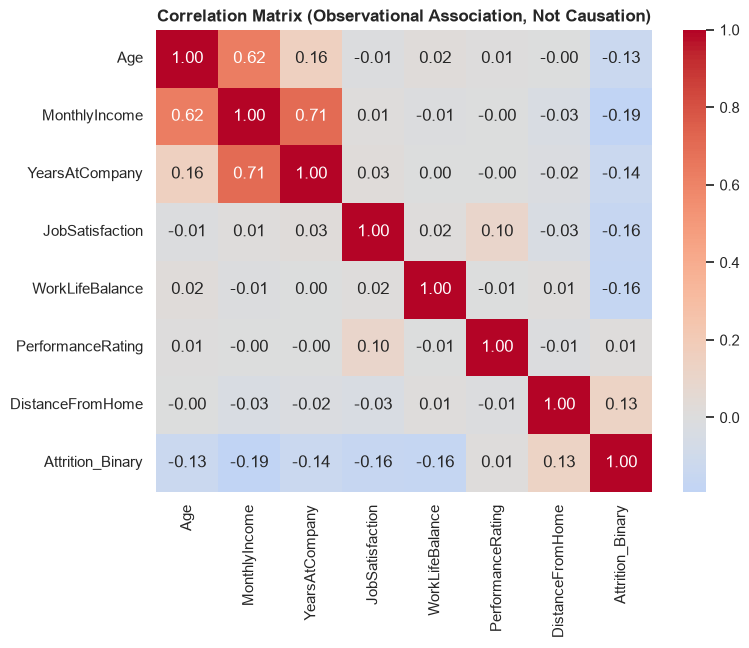

In [8]:
# Numerical Feature Correlations
num_df = df_clean.select_dtypes(include=[np.number]).drop(columns=['EmployeeID'], errors='ignore').copy()
num_df['Attrition_Binary'] = (df_clean['Attrition'] == 'Yes').astype(int)

plt.figure(figsize=(8, 6))
sns.heatmap(num_df.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Matrix (Observational Association, Not Causation)', fontweight='bold')
plt.show()

## 7. Data Preprocessing & Stratified Splitting
We split the dataset into stratified 80% training and 20% test sets to evaluate models without data leakage.

In [9]:
X_train, X_test, y_train, y_test = prepare_train_test_data(DATA_FILE, test_size=0.2, random_seed=42)
print(f"X_train shape: {X_train.shape}, y_train class 1 count: {y_train.sum()}")
print(f"X_test shape:  {X_test.shape},  y_test class 1 count: {y_test.sum()}")

[INFO] Dataset split successfully:
       Total records: 1000
       Training set: 800 samples (162 Attrition = Yes)
       Testing set:  200 samples (40 Attrition = Yes)
X_train shape: (800, 9), y_train class 1 count: 162
X_test shape:  (200, 9),  y_test class 1 count: 40


## 8. Machine Learning Model Training & Hyperparameter Tuning
We run `train_and_evaluate_models` from `src.train_model` which uses `GridSearchCV` on the training set to optimize Logistic Regression and Random Forest models.

In [10]:
comparison_df, best_metadata, champion_pipeline = train_and_evaluate_models(DATA_FILE)
comparison_df


      MACHINE LEARNING MODEL TRAINING & HYPERPARAMETER TUNING
[INFO] Dataset split successfully:
       Total records: 1000
       Training set: 800 samples (162 Attrition = Yes)
       Testing set:  200 samples (40 Attrition = Yes)

[TRAINING] Performing GridSearchCV on 'Logistic Regression'...


           Best CV F1: 0.5086
           Best Hyperparameters: {'classifier__C': 0.1, 'classifier__solver': 'lbfgs'}
           Test Accuracy : 0.7350
           Test Precision: 0.4110
           Test Recall   : 0.7500
           Test F1-Score : 0.5310
           Test ROC-AUC  : 0.7641

[TRAINING] Performing GridSearchCV on 'Random Forest'...


           Best CV F1: 0.5355
           Best Hyperparameters: {'classifier__max_depth': 6, 'classifier__min_samples_split': 10, 'classifier__n_estimators': 50}
           Test Accuracy : 0.7550
           Test Precision: 0.4151
           Test Recall   : 0.5500
           Test F1-Score : 0.4731
           Test ROC-AUC  : 0.7417

[SUCCESS] Model comparison saved to 'C:\Users\GAYATHRI\OneDrive\Desktop\Employee attrition\reports\model_comparison.csv'.
              Model                                                                                       Best_Params  CV_F1  Test_Accuracy  Test_Precision  Test_Recall  Test_F1_Score  Test_ROC_AUC
Logistic Regression                                             {'classifier__C': 0.1, 'classifier__solver': 'lbfgs'} 0.5086          0.735          0.4110         0.75         0.5310        0.7641
      Random Forest {'classifier__max_depth': 6, 'classifier__min_samples_split': 10, 'classifier__n_estimators': 50} 0.5355          0.755          0

[INFO] Generated feature importance plot at 'C:\Users\GAYATHRI\OneDrive\Desktop\Employee attrition\visuals\feature_importance.png'.
[SUCCESS] Saved champion metrics to 'C:\Users\GAYATHRI\OneDrive\Desktop\Employee attrition\reports\best_model_metrics.json'.
[SUCCESS] Saved complete fitted pipeline package to 'C:\Users\GAYATHRI\OneDrive\Desktop\Employee attrition\models\best_model.joblib'.


,Model,Best_Params,CV_F1,Test_Accuracy,Test_Precision,Test_Recall,Test_F1_Score,Test_ROC_AUC
0,Logistic Regression,"{'classifier__C': 0.1, 'classifier__solver': '...",0.5086,0.735,0.4110,0.75,0.5310,0.7641
1,Random Forest,"{'classifier__max_depth': 6, 'classifier__min_...",0.5355,0.755,0.4151,0.55,0.4731,0.7417


## 9. Model Evaluation Metrics & Champion Specifications

In [11]:
print(f"Selected Champion Model: {best_metadata['model_name']}")
print(f"Selection Rule: {best_metadata['selection_rule']}")
print("\nTest Metrics:")
for metric, val in best_metadata['test_metrics'].items():
    if metric not in ['confusion_matrix', 'classification_report']:
        print(f" - {metric:15s}: {val:.4f}")

print("\nConfusion Matrix [ [TN, FP], [FN, TP] ]:")
print(np.array(best_metadata['test_metrics']['confusion_matrix']))

Selected Champion Model: Logistic Regression
Selection Rule: Highest Test F1-Score with Stratified 5-Fold Cross-Validation

Test Metrics:
 - accuracy       : 0.7350
 - precision      : 0.4110
 - recall         : 0.7500
 - f1_score       : 0.5310
 - roc_auc        : 0.7641

Confusion Matrix [ [TN, FP], [FN, TP] ]:
[[117  43]
 [ 10  30]]


## 10. Model Feature Importance Analysis

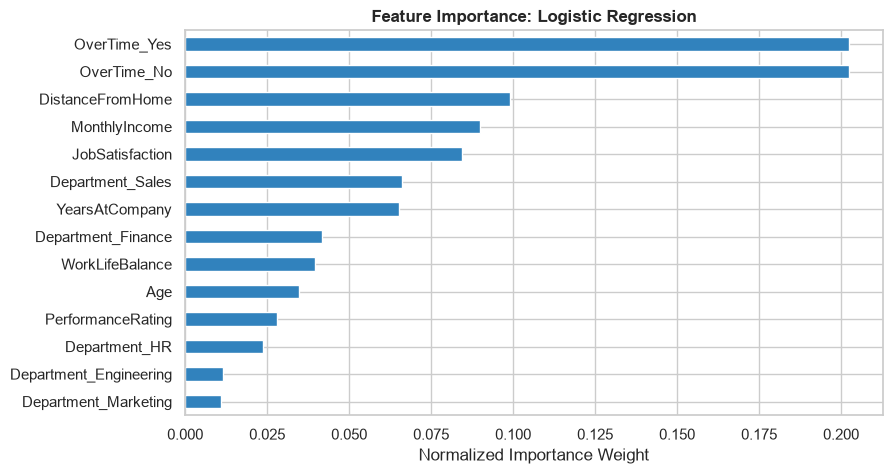

In [12]:
feat_importances = pd.Series(best_metadata['feature_importances']).sort_values(ascending=False)

plt.figure(figsize=(9, 5))
feat_importances.sort_values().plot(kind='barh', color='#3182bd')
plt.title(f"Feature Importance: {best_metadata['model_name']}", fontweight='bold')
plt.xlabel('Normalized Importance Weight')
plt.show()

## 11. Sample Real-Time Predictions
We test inference on sample employee records using `AttritionPredictor`.

In [13]:
predictor = AttritionPredictor()

# High risk sample
sample_risk = {
    "Age": 26,
    "Department": "Sales",
    "MonthlyIncome": 32000,
    "YearsAtCompany": 1,
    "JobSatisfaction": 1,
    "WorkLifeBalance": 1,
    "PerformanceRating": 3,
    "OverTime": "Yes",
    "DistanceFromHome": 35.0,
}

res_risk = predictor.predict_single(sample_risk)
print("Sample 1 (High Flight Risk Profile):")
print(f"Status: {res_risk['prediction_status']}")
print(f"Attrition Probability: {res_risk['attrition_probability_pct']}%")
print(f"Retention Probability: {res_risk['stay_probability_pct']}%")

# Low risk sample
sample_safe = {
    "Age": 45,
    "Department": "Engineering",
    "MonthlyIncome": 95000,
    "YearsAtCompany": 8,
    "JobSatisfaction": 5,
    "WorkLifeBalance": 4,
    "PerformanceRating": 4,
    "OverTime": "No",
    "DistanceFromHome": 5.0,
}

res_safe = predictor.predict_single(sample_safe)
print("\nSample 2 (Low Flight Risk Profile):")
print(f"Status: {res_safe['prediction_status']}")
print(f"Attrition Probability: {res_safe['attrition_probability_pct']}%")
print(f"Retention Probability: {res_safe['stay_probability_pct']}%")

Sample 1 (High Flight Risk Profile):
Status: Likely to Leave
Attrition Probability: 97.25%
Retention Probability: 2.75%

Sample 2 (Low Flight Risk Profile):
Status: Likely to Stay
Attrition Probability: 8.68%
Retention Probability: 91.32%
